# EDA Notebook

The purpose of this notebook is to preforme EDA on `../Data/WA_Fn-UseC_-Telco-Customer-Churn.csv` to know what needs to be processed/ changed to get the data ready for training.

## The main topics to be Explored on the DataFrame(df):
- The structure of df.
- Stats about df.
- Duplicates.
- Missing data, and any relation btween them.
- Destrbution of numarical data (Skew).
- Outliers.
- the size and destrbution of the target feature.
- Saving important info that may be needed for later.

## 1. Imports and configuration

In [18]:
# ------------------------- imports -------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [60]:
# ------------------------- Paths -------------------------
DATA = '../Data/WA_Fn-UseC_-Telco-Customer-Churn.csv'
RESULTS_DIR = '../Results/'

for d in ([RESULTS_DIR]):
    os.makedirs(d, exist_ok=True)
print("All project directories confirmed and ready.")

All project directories confirmed and ready.


In [20]:
# ------------------------- Var -------------------------
TARGET = "Churn"
RANDOM_STATE = 42

## 2. Load Data as DataFrame

In [21]:
# loading dataset, display 10 samples of it
df = pd.read_csv(DATA).drop(columns=['customerID'])
df.sample(5, random_state=RANDOM_STATE)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,Female,0,Yes,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,Male,0,No,No,41,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,Female,0,Yes,Yes,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,Female,0,No,No,1,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,Male,0,No,No,67,Yes,No,DSL,No,No,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


## 3. Dataset structure

In [22]:
numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="str").columns

print(f'Dataset Shape -> Customers: {df.shape[0]}, Features (without Target): {df.shape[1]}')
print('Dataset Dims: ', df.ndim)

print("\nNumerical columns:")
print(numeric_cols.tolist())

print("\nCategorical columns (with Traget):")
print(categorical_cols.tolist())

print()
df.info()

Dataset Shape -> Customers: 7043, Features (without Target): 20
Dataset Dims:  2

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical columns (with Traget):
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-

In [23]:
# Small Correction
df['SeniorCitizen'] = df['SeniorCitizen'].astype(str)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

numeric_cols = df.select_dtypes(include=np.number).columns
print("\nNumerical columns:")
print(numeric_cols.tolist())


Numerical columns:
['tenure', 'MonthlyCharges', 'TotalCharges']


In [24]:
categorical_cols = df.select_dtypes(include="str").columns

print('Unique Values for Categorical Features:')
for col in categorical_cols:
    print(f"\n----- {col} -----")
    print(df[col].nunique(), "unique values")
    print(df[col].value_counts().head(20)) # dropna=False

Unique Values for Categorical Features:

----- gender -----
2 unique values
gender
Male      3555
Female    3488
Name: count, dtype: int64

----- SeniorCitizen -----
2 unique values
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

----- Partner -----
2 unique values
Partner
No     3641
Yes    3402
Name: count, dtype: int64

----- Dependents -----
2 unique values
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

----- PhoneService -----
2 unique values
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

----- MultipleLines -----
3 unique values
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

----- InternetService -----
3 unique values
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

----- OnlineSecurity -----
3 unique values
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: cou

In [25]:
print('Unique Values for Numaric Features:')
for col in numeric_cols:
    print(f"\n----- {col} -----")
    print(df[col].nunique(), "unique values")
    print(df[col].value_counts().head(20)) # dropna=False

Unique Values for Numaric Features:

----- tenure -----
73 unique values
tenure
1     613
72    362
2     238
3     200
4     176
71    170
5     133
7     131
8     123
70    119
9     119
12    117
10    116
6     110
13    109
68    100
11     99
15     99
67     98
18     97
Name: count, dtype: int64

----- MonthlyCharges -----
1585 unique values
MonthlyCharges
20.05    61
19.85    45
19.95    44
19.90    44
19.70    43
19.65    43
20.00    43
20.15    40
19.55    40
19.75    39
20.25    39
19.80    38
20.35    38
19.60    37
20.10    37
20.20    35
19.50    32
19.40    31
20.45    31
20.40    30
Name: count, dtype: int64

----- TotalCharges -----
6530 unique values
TotalCharges
20.20    11
19.75     9
19.90     8
20.05     8
19.65     8
45.30     7
19.55     7
20.15     6
19.45     6
20.25     6
20.45     5
20.30     5
74.70     4
70.60     4
44.00     4
75.30     4
20.40     4
19.85     4
49.90     4
44.40     4
Name: count, dtype: int64


## 4. Dataset Stats for Numaric Features

In [26]:
df[numeric_cols].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


## 5. Explore Duplicates

In [27]:
print("Number of Duplicate Rows:", df.duplicated().sum())

# Droping Duplicates to not skew the data
df.drop_duplicates(inplace=True)

Number of Duplicate Rows: 22


## 6. Missing Values

In [28]:
missing_percent = df.isnull().mean() * 100
missing = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_percent
})

print(missing_table.sort_values("Missing %", ascending=False))

                  Missing Count  Missing %
TotalCharges                 11   0.156673
gender                        0   0.000000
Partner                       0   0.000000
SeniorCitizen                 0   0.000000
Dependents                    0   0.000000
tenure                        0   0.000000
MultipleLines                 0   0.000000
PhoneService                  0   0.000000
OnlineSecurity                0   0.000000
OnlineBackup                  0   0.000000
DeviceProtection              0   0.000000
InternetService               0   0.000000
TechSupport                   0   0.000000
StreamingTV                   0   0.000000
Contract                      0   0.000000
StreamingMovies               0   0.000000
PaperlessBilling              0   0.000000
PaymentMethod                 0   0.000000
MonthlyCharges                0   0.000000
Churn                         0   0.000000


In [29]:
columns_with_nan = df.isna().sum()
print('Columns with missing valeus:')
print(columns_with_nan[columns_with_nan > 0])

print(f'\nRows with missing values:')
rows_with_nan = df[df.isna().any(axis=1)]
print(rows_with_nan)

Columns with missing valeus:
TotalCharges    11
dtype: int64

Rows with missing values:
      gender SeniorCitizen Partner Dependents  tenure PhoneService  \
488   Female             0     Yes        Yes       0           No   
753     Male             0      No        Yes       0          Yes   
936   Female             0     Yes        Yes       0          Yes   
1082    Male             0     Yes        Yes       0          Yes   
1340  Female             0     Yes        Yes       0           No   
3331    Male             0     Yes        Yes       0          Yes   
3826    Male             0     Yes        Yes       0          Yes   
4380  Female             0     Yes        Yes       0          Yes   
5218    Male             0     Yes        Yes       0          Yes   
6670  Female             0     Yes        Yes       0          Yes   
6754    Male             0      No        Yes       0          Yes   

         MultipleLines InternetService       OnlineSecurity  \
488   No

In [32]:
same_value_cols = rows_with_nan.columns[rows_with_nan.nunique() == 1].tolist()
print('Columns with the same Value for the missing data rows:')
rows_with_nan[same_value_cols]

Columns with the same Value for the missing data rows:


,SeniorCitizen,Dependents,tenure,Churn
488,0,Yes,0,No
753,0,Yes,0,No
936,0,Yes,0,No
1082,0,Yes,0,No
1340,0,Yes,0,No
3331,0,Yes,0,No
3826,0,Yes,0,No
4380,0,Yes,0,No
5218,0,Yes,0,No
6670,0,Yes,0,No


In [38]:
compare_df = pd.DataFrame()
compare_df['TotalCharges'] = df['TotalCharges'].copy()
compare_df['ExpectedTotalCharges'] = df['MonthlyCharges'] * df['tenure']
compare_df['OffsetbetweenCharges'] = np.abs(df['TotalCharges'] - compare_df['ExpectedTotalCharges'])
print(f'The mean of the Offset between TotalCharges & ExpectedTotalCharges: ',np.mean(compare_df['OffsetbetweenCharges']))

compare_df[['TotalCharges', 'ExpectedTotalCharges', 'OffsetbetweenCharges']]

The mean of the Offset between TotalCharges & ExpectedTotalCharges:  45.23066333808845


,TotalCharges,ExpectedTotalCharges,OffsetbetweenCharges
0,29.85,29.85,0.00
1,1889.50,1936.30,46.80
2,108.15,107.70,0.45
3,1840.75,1903.50,62.75
4,151.65,141.40,10.25
...,...,...,...
7038,1990.50,2035.20,44.70
7039,7362.90,7430.40,67.50
7040,346.45,325.60,20.85
7041,306.60,297.60,9.00


## 7. Univariate analysis (Distrbution & Skew)

In [48]:
def get_dest(name):
    skewness = df[name].skew()
    print(f'Skew for {name} feature: {skewness*100}%')

    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=name, bins=30, kde=True)
    plt.title(f"{name} Distribution")
    plt.show()

    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x=name)
    plt.title(f"{name} Boxplot")
    plt.show()

Skew for tenure feature: 23.554168006988707%


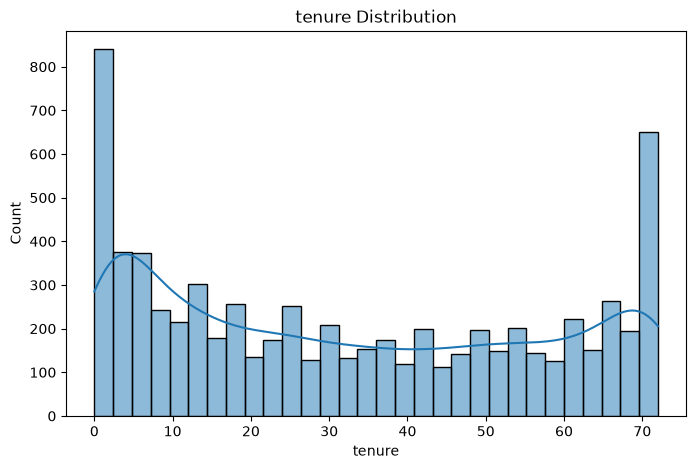

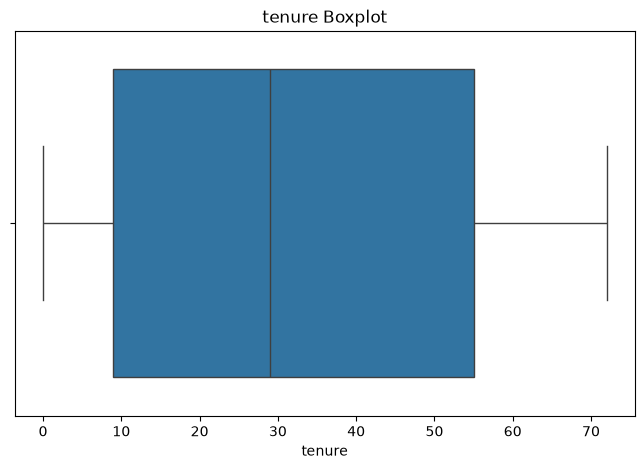

In [49]:
# Tenure
get_dest('tenure')

Skew for MonthlyCharges feature: -22.409728909692607%


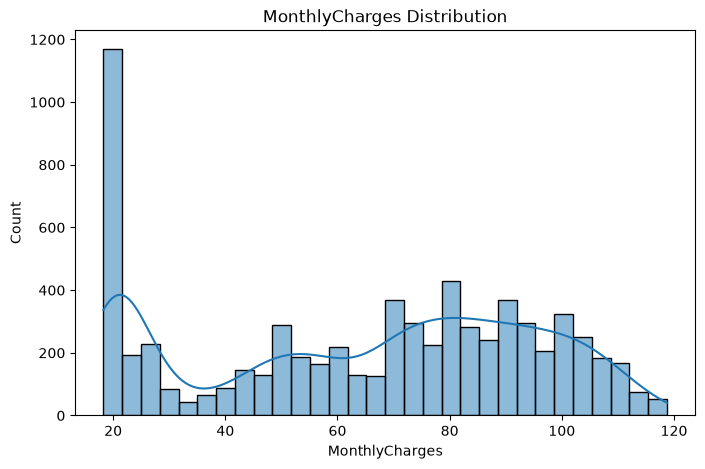

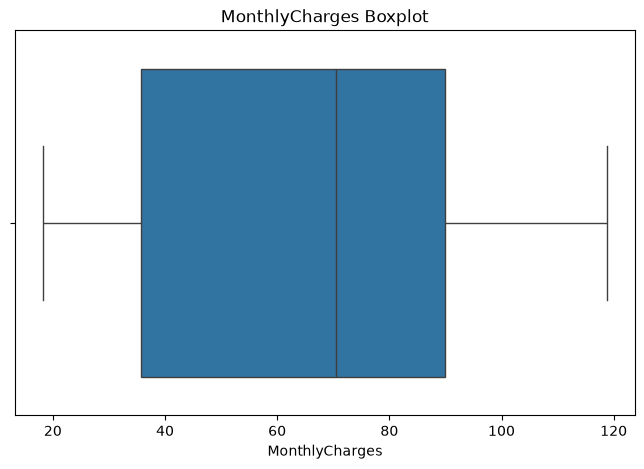

In [50]:
# MonthlyCharges
get_dest('MonthlyCharges')

Skew for TotalCharges feature: 95.83220586626408%


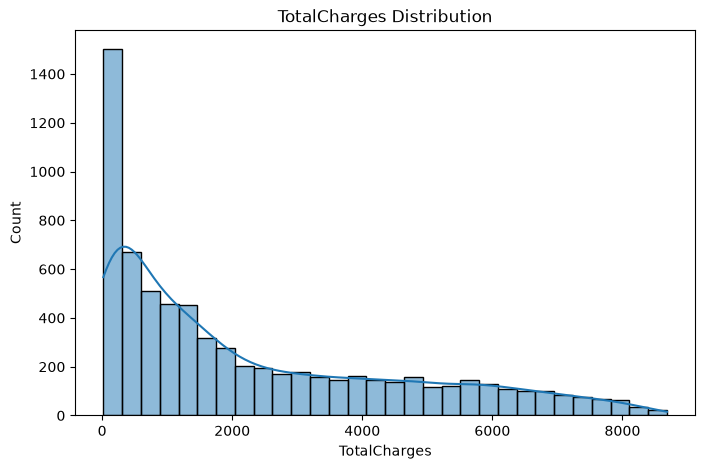

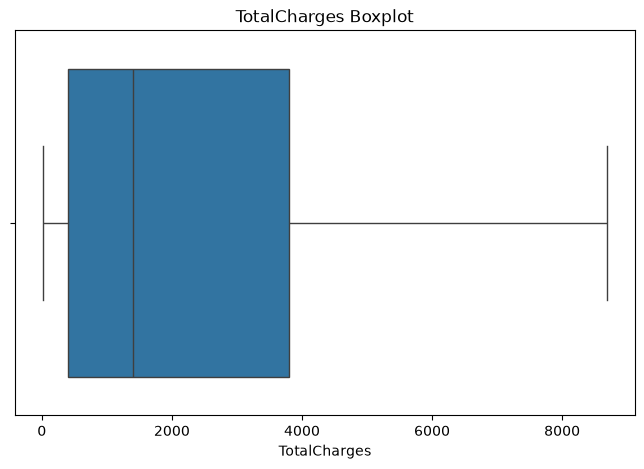

In [51]:
# TotalCharges
get_dest('TotalCharges')

## 8. Outliers

In [ ]:
for i in numeric_cols:
    print("\n",'-'*34,i,'-'*34)
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print("Lower:", lower_bound)
    print("Upper:", upper_bound)

    outliers = df[(df[i] < lower_bound) |(df[i] > upper_bound)]
    if len(outliers): print(outliers)

    print("Number of outliers:", len(outliers))


 ---------------------------------- tenure ----------------------------------
Lower: -60.0
Upper: 124.0
Number of outliers: 0

 ---------------------------------- MonthlyCharges ----------------------------------
Lower: -45.47500000000001
Upper: 171.125
Number of outliers: 0

 ---------------------------------- TotalCharges ----------------------------------
Lower: -4690.975
Upper: 8907.125
Number of outliers: 0


## 9. Suspicious Values

To Find values that makes no sence in Numaric data, Like: Negative Numarical Values in tenure.

In [53]:
for i in numeric_cols:
    print("\n",'-'*20,i,'-'*20)
    sus_valeus = df[df[i] < 0]
    if len(sus_valeus): 
        print(outliers)

    else:
        print('No suspicous values')


 -------------------- tenure --------------------
No suspicous values

 -------------------- MonthlyCharges --------------------
No suspicous values

 -------------------- TotalCharges --------------------
No suspicous values


## 10. Target Variable

In [59]:
tagret_values = df[TARGET].value_counts()
print(tagret_values)

ratio = tagret_values.iloc[0] / tagret_values.iloc[1]
print(f'\nRatio between `{tagret_values.index[1]}` & `{tagret_values.index[0]}` = 1 : {ratio:.2f}')

Churn
No     5164
Yes    1857
Name: count, dtype: int64

Ratio between `Yes` & `No` = 1 : 2.78


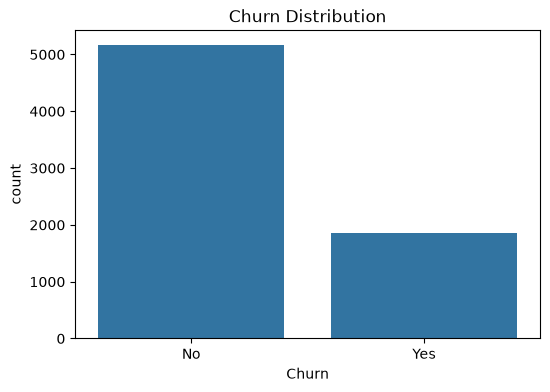

In [57]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET)
plt.title(f"{TARGET} Distribution")
plt.show()